In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv('train.tsv', sep="\t")

df = df.drop_duplicates()
df.head()

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3
0,0,"и,чё,блядь где этот херой был до этого со свои...","Ну и где этот герой был,со своими доказательст...",Где этот герой был до этого со своими доказате...,"и,где этот герой был до этого со своими доказа..."
1,1,"О, а есть деанон этого петуха?","О, а есть деанон",NaN,NaN
2,2,"херну всякую пишут,из-за этого лайка.долбоебизм.","Чушь всякую пишут, из- за этого лайка.","Ерунду всякую пишут,из-за этого лайка.",NaN
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,Из-за таких людей мы и страдаем,из за таких как он мы и страдаем
4,4,гондон путинский он а не артист,"Человек Путина он, а не артист",NaN,NaN


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6948 entries, 0 to 6947
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   index             6948 non-null   int64 
 1   toxic_comment     6948 non-null   object
 2   neutral_comment1  6948 non-null   object
 3   neutral_comment2  3150 non-null   object
 4   neutral_comment3  992 non-null    object
dtypes: int64(1), object(4)
memory usage: 271.5+ KB


In [3]:
import re

In [4]:
def beautify(text):
    text = str(text).lower().strip()
    text = re.sub(r'http\S+', '', text)
    text = re.sub(r'www\S+', '', text)
    text = re.sub(r"\'s", " ", text)
    text = re.sub('\W', ' ', text)
    text = re.sub('\s+', ' ', text)
    if text == None:
      return ""
    return text

df['toxic_comment'] = df['toxic_comment'].apply(beautify)
df['neutral_comment1'] = df['neutral_comment1'].apply(beautify)
df['neutral_comment2'] = df['neutral_comment2'].apply(beautify)
df['neutral_comment3'] = df['neutral_comment3'].apply(beautify)

In [5]:
df[:5]

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3
0,0,и чё блядь где этот херой был до этого со свои...,ну и где этот герой был со своими доказательст...,где этот герой был до этого со своими доказате...,и где этот герой был до этого со своими доказа...
1,1,о а есть деанон этого петуха,о а есть деанон,nan,nan
2,2,херну всякую пишут из за этого лайка долбоебизм,чушь всякую пишут из за этого лайка,ерунду всякую пишут из за этого лайка,nan
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,из за таких людей мы и страдаем,из за таких как он мы и страдаем
4,4,гондон путинский он а не артист,человек путина он а не артист,nan,nan


Избавимся от аномально коротких или длинных сообещений.
Для этого для начала посмотрим на распределение длины токсичных сообщений

Анализировать в дальнейшем будем именно колонку с токсичными сообщениями, так как остальные - это уже переделанные исходные.

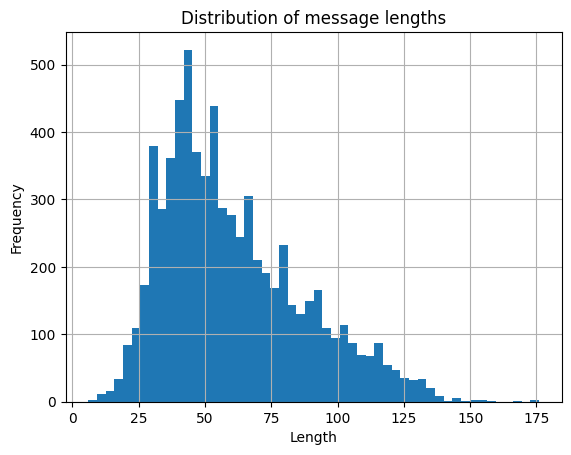

In [6]:
import matplotlib.pyplot as plt


df.apply(lambda x: len(x['toxic_comment']), axis=1).hist(bins=52)
plt.xlabel('Length')
plt.ylabel('Frequency')
plt.title('Distribution of message lengths')
plt.show()

Из графика видно, что разумно почистить например сообщения длины > 130. Коротких сообщений мало, но даже трехбуквенное сообщение может оказаться вполне себе токсичным, так что короткие чистить не будем

In [7]:

df = df[(df['toxic_comment'].apply(lambda x: len(x)) < 130)]
df.shape

(6866, 5)

In [8]:
df['sentence_count'] = df['toxic_comment'].apply(lambda x: x.count('. '))

In [9]:
import nltk

nltk.download('punkt')
nltk.download('stopwords')

from nltk import word_tokenize
from nltk.probability import FreqDist
from nltk.corpus import stopwords
from nltk.util import ngrams

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


<Axes: title={'center': 'Анализ вхождений'}, xlabel='Samples', ylabel='Counts'>

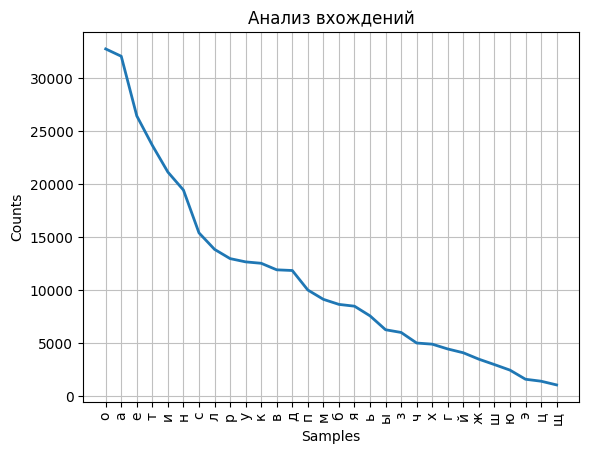

In [11]:
# Частота вхождений слов
comments = " ".join(beautify(df['toxic_comment'].tolist()))


# избавимся от пунктуации в подсчете
tokenizer = nltk.RegexpTokenizer(r'\w+')

tokens = tokenizer.tokenize(comments)
text = nltk.Text(tokens)
dist = FreqDist(text)
dist.plot(30, cumulative=False, title='Анализ вхождений')

<Axes: title={'center': '2_grams'}, xlabel='Samples', ylabel='Counts'>

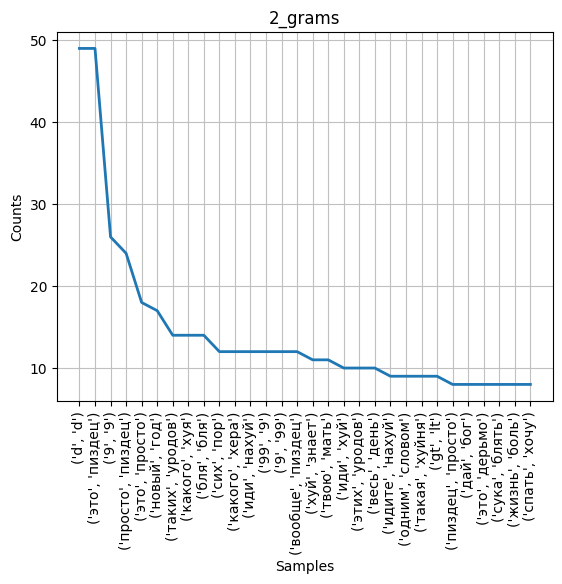

In [12]:
from functools import reduce

df['tokenized'] = df['toxic_comment'].apply(lambda x: tokenizer.tokenize(x)).apply(lambda x: [word  for word in x if word not in stopwords.words("russian")])
df['2_grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 2)))
bigrams = reduce(lambda x, y: x + y, df['2_grams'].values)
dist = FreqDist(bigrams)
dist.plot(30, cumulative=False, title='2_grams')

У нас не безумно большой датасет, поэтому 3-грамм не так уж и много. Это подтверждается и графиком ниже

(('d', 'd', 'd'), 30)
(('это', 'просто', 'пиздец'), 10)
(('9', '9', '9'), 10)
(('бля', 'бля', 'бля'), 4)
(('мало', 'мало', 'мало'), 4)


<Axes: title={'center': '3_grams'}, xlabel='Samples', ylabel='Counts'>

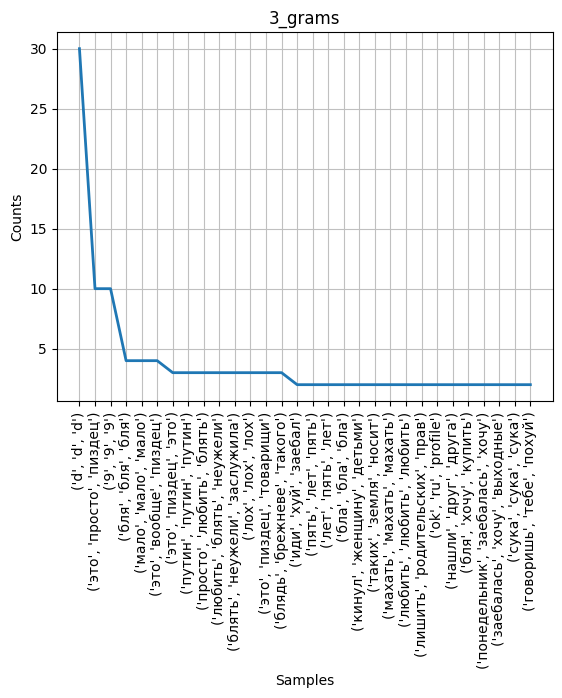

In [14]:
df['3_grams'] = df['tokenized'].apply(lambda x: list(ngrams(x, 3)))
threegrams = reduce(lambda x, y: x + y, df['3_grams'].values)
dist = FreqDist(threegrams)
print('\n'.join(map(str, dist.most_common(5))))
dist.plot(30, cumulative=False, title='3_grams')

Чтож, вполне ожидаемый результат))

In [ ]:
!pip install pymorphy2
import pymorphy2

Посмотрим на стемминг.

('сук', 523)
('пиздец', 484)
('так', 460)
('блят', 386)
('бля', 306)


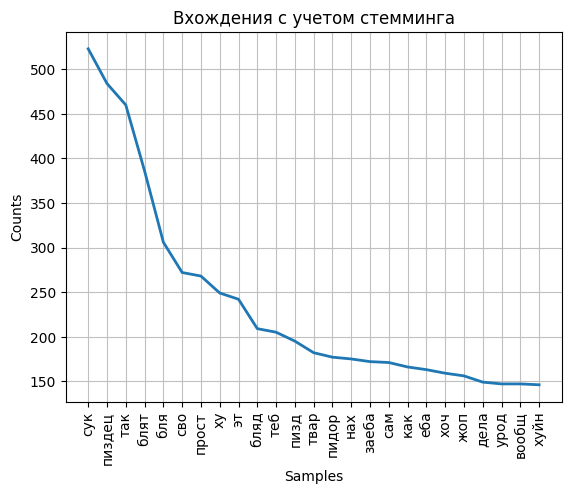

<Axes: title={'center': 'Вхождения с учетом стемминга'}, xlabel='Samples', ylabel='Counts'>

In [ ]:

from nltk.stem.snowball import SnowballStemmer


stemmer = SnowballStemmer(language='russian')
stemmed = map(lambda word: stemmer.stem(word), text1)
distr = FreqDist(stemmed)
print('\n'.join(map(str, distr.most_common(5))))
distr.plot(25, cumulative=False, title='Вхождения с учетом стемминга')

In [ ]:
# Теперь сохраним предложения с учетом стемминга
df['stemmed_toxic'] = df['toxic_comment'].apply(lambda x: " ".join([stemmer.stem(y) for y in x.split()]))

In [ ]:
df.head()

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3,tokenized,2_grams,3_grams,stemmed_toxic
0,0,и чё блядь где этот херой был до этого со свои...,ну и где этот герой был со своими доказательст...,где этот герой был до этого со своими доказате...,и где этот герой был до этого со своими доказа...,"[чё, блядь, херой, своими, доказательствами]","[(чё, блядь), (блядь, херой), (херой, своими),...","[(чё, блядь, херой), (блядь, херой, своими), (...",и че бляд где этот хер был до эт со сво доказа...
1,1,о а есть деанон этого петуха,о а есть деанон,nan,nan,"[деанон, петуха]","[(деанон, петуха)]",[],о а ест деанон эт петух
2,2,херну всякую пишут из за этого лайка долбоебизм,чушь всякую пишут из за этого лайка,ерунду всякую пишут из за этого лайка,nan,"[херну, всякую, пишут, лайка, долбоебизм]","[(херну, всякую), (всякую, пишут), (пишут, лай...","[(херну, всякую, пишут), (всякую, пишут, лайка...",херн всяк пишут из за эт лайк долбоебизм
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,из за таких людей мы и страдаем,из за таких как он мы и страдаем,"[таких, пидоров, страдаем]","[(таких, пидоров), (пидоров, страдаем)]","[(таких, пидоров, страдаем)]",из за так пидор мы и страда
4,4,гондон путинский он а не артист,человек путина он а не артист,nan,nan,"[гондон, путинский, артист]","[(гондон, путинский), (путинский, артист)]","[(гондон, путинский, артист)]",гондон путинск он а не артист


А теперь посмотрим на n граммы после применения стемминга.

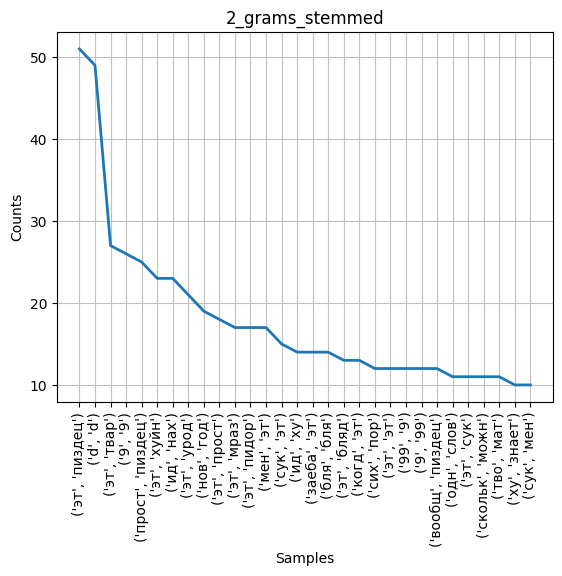

<Axes: title={'center': '2_grams_stemmed'}, xlabel='Samples', ylabel='Counts'>

In [ ]:
from functools import reduce

df['tokenized_stemmed'] = df['stemmed_toxic'].apply(lambda x: tokenizer.tokenize(x)).apply(lambda x: [str(word)  for word in x if word not in stopwords.words("russian")])
df['2_grams_stemmed'] = df['tokenized_stemmed'].apply(lambda x: list(ngrams(x, 2)))
bigrams = reduce(lambda x, y: x + y, df['2_grams_stemmed'].values)
dist = FreqDist(bigrams)
dist.plot(30, cumulative=False, title='2_grams_stemmed')

(('d', 'd', 'd'), 30)
(('эт', 'прост', 'пиздец'), 10)
(('9', '9', '9'), 10)
(('ид', 'ху', 'сво'), 4)
(('бля', 'бля', 'бля'), 4)


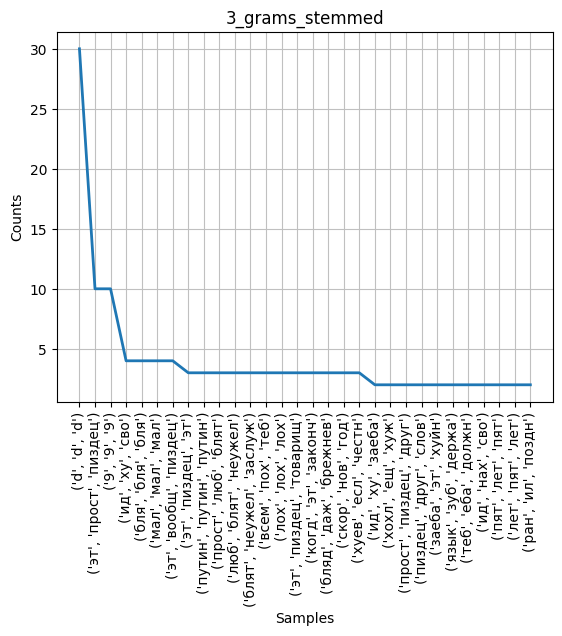

<Axes: title={'center': '3_grams_stemmed'}, xlabel='Samples', ylabel='Counts'>

In [ ]:
df['3_grams_stemmed'] = df['tokenized_stemmed'].apply(lambda x: list(ngrams(x, 3)))
threegrams = reduce(lambda x, y: x + y, df['3_grams_stemmed'].values)
dist = FreqDist(threegrams)
print('\n'.join(map(str, dist.most_common(5))))
dist.plot(30, cumulative=False, title='3_grams_stemmed')

In [ ]:
После построения n-грамм с учетом стемминга, видно логично влияние
Пар и троек по смыслу стало больше.

Посмотрим на лемматизацию.

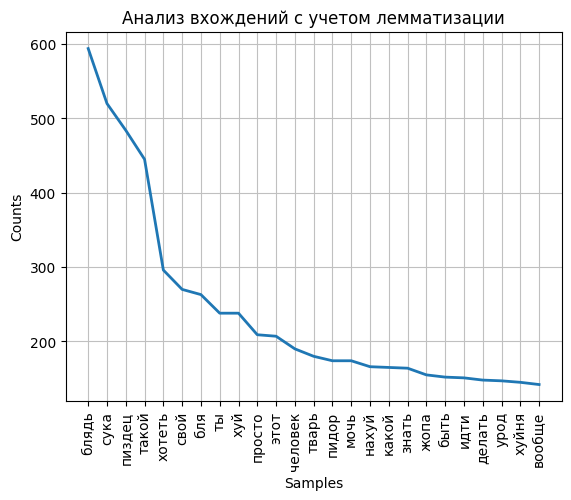

<Axes: title={'center': 'Анализ вхождений с учетом лемматизации'}, xlabel='Samples', ylabel='Counts'>

In [ ]:


morph = pymorphy2.MorphAnalyzer()

lemmatized = map(lambda word: morph.parse(word)[0].normal_form, text1)
distr = FreqDist(lemmatized)
distr.plot(25, cumulative=False, title='Анализ вхождений с учетом лемматизации')

**Результат:**
Датасет подходит для дальнейшей работы, как видно из графиков в нем много показательных и плохих слов, которые хорошо приводятся к нормальной форме. Популярные ругательства встречаются сотни раз. У ругательств в основном много общих корней, как видно из проделанных выше процедур.
Данные оказалось не так трудно почистить от пунктуации, тэгов и прочих добавок, мешающих конструктивному анализу.

## **Третий чекпоинт**

Здесь мы поработаем с различными моделями, а не просто с анализом текстов.
Начнем с линейной модели. Построим словарь частых слов в нашей базе и присвоим им веса.
Очень плохим словам, имеющим весомый вклад в общую злобу фразы присвоим вес 3.
Словам плохим, но не настолько 1 или 2. Нейтральным или хорошим словам присвоим веса от -1 до 0.
Такое неравномерное распределение разумно, так как наличие плохого слова в предложении делает его более негативным, чем наличие хорошего - добрым.

Можно сказать, что при наличии одного матерного слова, нужно несколько хороших, чтобы предложение стало хоть немного более сглаженным.

In [28]:
import nltk
nltk.download('punkt_tab')
from collections import Counter

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6948 entries, 0 to 6947
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   index             6948 non-null   int64 
 1   toxic_comment     6948 non-null   object
 2   neutral_comment1  6948 non-null   object
 3   neutral_comment2  3150 non-null   object
 4   neutral_comment3  992 non-null    object
dtypes: int64(1), object(4)
memory usage: 271.5+ KB


In [31]:
def count_word_occurrences_filtered(df, column_name, min_count=5):
    stop_words = set(stopwords.words('russian')) # Используем русский стоп-лист
    prepositions = {"в", "на", "к", "от", "до", "из", "с", "по", "для", "через", "около", "перед", "за", "между", "из-за", "благодаря", "вопреки", "согласно", "вместо", "помимо", "кроме", "вне", "внутри"} # Добавьте нужные предлоги


    all_words = []
    for text in df[column_name]:
        if isinstance(text, str):
            words = word_tokenize(text.lower())
            words = [w for w in words if w.isalnum() and w not in stop_words and w not in prepositions]
            all_words.extend(words)

    word_counts = Counter(all_words)
    filtered_word_counts = {word: count for word, count in word_counts.items() if count >= min_count}

    return filtered_word_counts


# Пример использования:
data = {'text': ['Это пример текста с предлогами в и на.', 'Другой пример текста, без предлогов.', 'Текст, текст, еще текст!']}
import pandas as pd
import numpy as np
df = pd.read_csv('train.tsv', sep="\t")

filtered_word_counts = count_word_occurrences_filtered(df, 'toxic_comment')

words = []
for word, count in filtered_word_counts.items():
  words.append([word, count])

words = sorted(words, key=lambda x: -x[1])

# чтобы не занимало место закомментим
#for k, v in words[:100]:
#  print(f"{k}:  {v}")


это:  616
пиздец:  473
блять:  374
сука:  371
бля:  256
просто:  209
тебе:  199
блядь:  165
хуй:  165
хочу:  154
нахуй:  150
вообще:  140
ещё:  132
всё:  114
таких:  104
почему:  102
9:  102
такие:  92
могу:  88
суки:  87
ебать:  87
че:  83
сегодня:  82
этих:  81
твари:  79
эта:  78
пидор:  77
такое:  75
хуйня:  75
делать:  75
завтра:  74
жопу:  71
мразь:  69
очень:  69
пизда:  66
день:  66
тварь:  65
иди:  64
блин:  63
сколько:  62
такая:  60
нужно:  59
уроды:  58
буду:  58
дома:  57
говно:  55
пусть:  54
людей:  53
деньги:  53
всем:  52
народ:  51
дура:  51
сразу:  51
заебали:  50
99:  50
d:  49
пидоры:  49
ненавижу:  49
лох:  49
хуйню:  48
люди:  48
этим:  47
похуй:  47
жопа:  47
дебил:  46
время:  46
её:  45
свой:  45
чмо:  45
болит:  45
хуя:  44
дебилы:  44
кого:  44
чо:  44
нихуя:  43
весь:  43
нам:  42
мудак:  42
какого:  42
походу:  42
люблю:  42
урод:  41
сама:  41
лет:  40
та:  40
мама:  40
спать:  40
пока:  39
россии:  38
жить:  38
жизнь:  38
жизни:  38
ебаный:  38
хуево:  3

Датасета или словаря, где у всех слов уже были бы проставлены веса доброты/злости я не нашел, веса придется проставить руками.

In [34]:
#for k, v in words[:100]:
#  print(f'"{k}":  ,')

In [73]:
weights = {
    "это":  0,"пиздец":  3, "блять":  3,"сука":  3,"бля":  3, "просто":  0,
"тебе":  0,"блядь":  3,"хуй":  3,"хочу":  0,"нахуй":  3,"вообще":  0,"ещё":  0,
"всё":  0,"таких":  0,"почему":  0,"такие":  0,"могу":  0,"суки":  2,"ебать":  3,"че":  1,"сегодня":  0,"этих":  0,
"твари":  2,"эта":  0,"пидор":  3,"такое":  1,"хуйня":  3,"делать":  0,"завтра":  0,"жопу":  1,"мразь":  3,"очень":  0,"пизда":  3,"день":  0,"тварь":  3,
"иди":  1,"блин":  1,"сколько":  0,"такая":  0,"нужно":  0,"уроды":  2,"буду":  0,"дома":  0,"говно":  1,
"пусть":  0,"людей":  0, "маму": 3, "долбоебизм":3, "пидоров": 2,
"деньги":  0,"всем":  0,"народ":  -1,"дура":  1,"сразу":  0,"заебали":  2,"пидоры":  3,"ненавижу":  1,"лох":  1,
"хуйню":  3,"люди":  0,"этим":  0,"похуй":  3,"жопа":  1,
"дебил":  2,"время":  0,"её":  0,"свой":  0,
"чмо":  2,"болит":  0, "гондон": 3, "петуха": 3,
"хуя":  2,"дебилы":  2,"мудак":  3,
"урод":  2,"мама":  3,
"ебаный":  3,"хуево":  1,
"заебал":  3,"долбоеб":  3,
"плохо":  1
}

На словарь выше я потратил около 3 минут времени и руками проставил веса словам. Как и описано выше - максимум 3 - самые токсичные слова.

Теперь посмотрим на популярные слова из нейтральных комментариев.
Как видно, они все хорошие. Причем даже негативные слова тут будут весить отрицательное количество очков. Если человек пишет например слово "ужас" в своем предложении, он почти точно выражает негативную мысль, но не выходит за рамки и такие предложения точно не злые.

In [74]:
filtered_word_counts = count_word_occurrences_filtered(df, 'neutral_comment3')

words = []
for word, count in filtered_word_counts.items():
  words.append([word, count])

words = sorted(words, key=lambda x: -x[1])
# for k, v in words[:100]:
#   print(f"{k}:  {v}")

In [51]:
#for k, v in words[:100]:
#   print(f'"{k}":  ,')

In [75]:
not_toxic_weights = {
    "сижу":  -1,
    "надоел":  -1,
    "нечего":  -1,
    "надоели":  -1,
    "смешно":  -2,
    "голове": -1 ,
    "домой":  -1,
    "плохой":  -1,
    "плохая":  -1,
    "боюсь":  -1,
    "надоело":  -1,
    "детей":  -1,
    "жить":  -1,
    "шоке":  -1,
    "конец":  -1,
    "капец":  -1,
    "потеряла":  -1,
    "скучно":  -1,
    "школу":  -1,
    "устала": -1 ,
    "правильно":  -2,
    "любить":  -3,
    "пусть":  -1
}

# объединим словари
for k in not_toxic_weights:
  weights[k] = not_toxic_weights[k]


In [76]:
import string

def replace_punctuation_with_space_custom(text, punctuation_to_replace = string.punctuation+"?!"):
    """Заменяет заданные знаки препинания на пробелы, используя регулярные выражения.
    Позволяет указать, какие знаки препинания нужно заменить.
    """
    pattern = '[' + re.escape(punctuation_to_replace) + ']'
    cleaned_text = re.sub(pattern, ' ', text)
    return cleaned_text



def rate_comment(text):
  score = 0
  for w in replace_punctuation_with_space_custom(text).strip().lower().split():
    if w in weights:
      score += weights[w]
  return score

# Пример работы функции
print(rate_comment("Иди нахуй долбоеб"))
print(rate_comment("Я твою маму на хую вертел"))
print(rate_comment("Заниматься этим было откровенно скучно"))



7
3
-1


In [84]:
# Теперь давайте применим такую оценку к колонке с токсичными комментариями.
df['toxic_score'] = df['toxic_comment'].apply(lambda x: rate_comment(x))

# Теперь давайте применим такую оценку к колонке с нейтральным комментариями.
df['neutral1_score'] = df['neutral_comment1'].apply(lambda x: rate_comment(x))

In [85]:
df.head(5)

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3,toxic_score,neutral1_score
0,0,"и,чё,блядь где этот херой был до этого со свои...","Ну и где этот герой был,со своими доказательст...",Где этот герой был до этого со своими доказате...,"и,где этот герой был до этого со своими доказа...",3,0
1,1,"О, а есть деанон этого петуха?","О, а есть деанон",NaN,NaN,3,0
2,2,"херну всякую пишут,из-за этого лайка.долбоебизм.","Чушь всякую пишут, из- за этого лайка.","Ерунду всякую пишут,из-за этого лайка.",NaN,3,0
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,Из-за таких людей мы и страдаем,из за таких как он мы и страдаем,2,0
4,4,гондон путинский он а не артист,"Человек Путина он, а не артист",NaN,NaN,3,0


Итак, каждому токсичному комменту мы посчитали скор по нашей простой модели. Давайте посмотрим для какого процента токсичных комментариев мы получили положительный скор

In [88]:

print(len(df[df["toxic_score"] > 0]) / len(df))
print(len(df[df["neutral1_score"] > 0]) / len(df))

0.45451928612550374
0.0590097869890616


Ожидаемо модель работает не очень хорошо
Половину токчисных комментариев мы определили как токсичные (скор > 0)
Каждый двадцатый нейтральный мы определили как токсичный.
Для такой простой модели результат хороший

# **Теперь попробуем чуть расширить модель, чтобы она стала rule based**

In [95]:
import string

def toxicity_rule_based(text, threshold=1):
    text = text.lower()
    words = text.split()
    punctuation_count = sum(1 for char in text if char in string.punctuation)


    # Добавим признаки из условия
    text_length = len(text)
    word_count = len(words)
    avg_word_length = text_length / word_count if word_count > 0 else 0
    punctuation_ratio = punctuation_count / text_length if text_length > 0 else 0

    # Используем функцию, которую реализовали выше самостоятельно
    toxicity_score = rate_comment(text)
    toxic_count = 0
    for w in words:
      if w in weights and weights[w] > 0:
        toxic_count += 1


    # Добавление баллов за количество токсичных слов
    toxicity_score += toxic_count * 0.2

    # Добавление баллов на основе других признаков
    if word_count > 20:       toxicity_score += 2  # Длинные сообщения могут быть более токсичными
    if punctuation_ratio > 0.1: toxicity_score += 1  # Много знаков препинания может указывать на агрессию
    if avg_word_length < 3:  toxicity_score += 1  # Короткие слова могут быть признаком агрессии или спама


    # Проверка на токсичность
    return toxicity_score




In [101]:
df['toxic_rule_based_score'] = df['toxic_comment'].apply(lambda x: toxicity_rule_based(x))
df['neutral1_rule_based_score'] = df['neutral_comment1'].apply(lambda x: toxicity_rule_based(x))


In [98]:
df.head(5)

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3,toxic_score,neutral1_score,toxic_rule_based_score
0,0,"и,чё,блядь где этот херой был до этого со свои...","Ну и где этот герой был,со своими доказательст...",Где этот герой был до этого со своими доказате...,"и,где этот герой был до этого со своими доказа...",3,0,3.0
1,1,"О, а есть деанон этого петуха?","О, а есть деанон",NaN,NaN,3,0,3.0
2,2,"херну всякую пишут,из-за этого лайка.долбоебизм.","Чушь всякую пишут, из- за этого лайка.","Ерунду всякую пишут,из-за этого лайка.",NaN,3,0,3.0
3,3,из за таких пидоров мы и страдаем,из за таких плохих людей мы и страдаем,Из-за таких людей мы и страдаем,из за таких как он мы и страдаем,2,0,2.2
4,4,гондон путинский он а не артист,"Человек Путина он, а не артист",NaN,NaN,3,0,3.2


Подобрать пороги достаточно сложно. Можно провести разные эксперименты, но на самом деле признаки которые тут можно использовать в любом случае сомнительные, как по мне.
Я попробовал несколько комбинаций порогов, давайте посмотрим что получилось улучшить.

In [102]:

# Напоминаю, что тут мы смотрим на соотношение мест, где метрика дала верный результат
# и мест, где она должна была дать верный результат
print(len(df[df["toxic_rule_based_score"] > 0]) / len(df))

# а тут смотрим то же, но только смотрим места, где метрика показала токсичность > 0 при проверке нейтрального коммента
print(len(df[df["neutral1_rule_based_score"] > 0]) / len(df))

0.5542602187679908
0.13169257340241797


Как видно, получилось определять больше токсичных комментариев. Но количество false positive определений тоже возросло.


# **BoW/TF-IDF + logReg/SVM/boosting**

Для начала объединим токсичные комменты с нейтральными и проставим им в соответствие значения переменной is_toxic
Теперь мы можем работать с датасетом в привычном формате, разбивая его на разные выборки

In [116]:
df = pd.read_csv('train.tsv', sep="\t")

df = df.drop_duplicates()

In [117]:
df['comment'] = df['toxic_comment']
df['is_toxic'] = 1
df_neutral = pd.DataFrame({'comment': df['neutral_comment1'], "is_toxic": 0})

df = pd.concat([df, df_neutral], ignore_index=True)



In [152]:
results = []

In [134]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, classification_report
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize


# Стоп-слова
nltk.download('stopwords')
nltk.download('punkt')
stop_words = set(stopwords.words('russian'))

# Предобработка текста
def preprocess_text(text):
    tokens = word_tokenize(text.lower())
    return [word for word in tokens if word.isalnum() and word not in stop_words]

df['processed_comment'] = df['comment'].apply(preprocess_text)

# Cобственно, BoW векторы
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(df['processed_comment'].apply(' '.join))
y = df['is_toxic'].values





[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


# **BoW + LogReg**

In [150]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Теперь регрессия
model = LogisticRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")



Точность: 0.739568345323741
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.69      0.85      0.76      1367
           1       0.82      0.63      0.71      1413

    accuracy                           0.74      2780
   macro avg       0.75      0.74      0.74      2780
weighted avg       0.75      0.74      0.74      2780

[['BoW + LogReg', '      0.75      0.74      0.74      2780\n']]
Точность: 0.739568345323741
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.69      0.85      0.76      1367
           1       0.82      0.63      0.71      1413

    accuracy                           0.74      2780
   macro avg       0.75      0.74      0.74      2780
weighted avg       0.75      0.74      0.74      2780

[['BoW + LogReg', '      0.75      0.74      0.74      2780\n'], ['BoW + LogReg', '      0.75      0.74      0.74      2780\n']]


Чтобы собрать в конце удобную табличку напишем костыльный способ извлечь из отчета нужные данные

In [154]:
def extract_report(report):
  return report[report.find('weighted avg')+13:].strip()

results.append(["BoW+logreg"] + [extract_report(report)])


[['BoW+logreg', '0.75      0.74      0.74      2780']]


# **BoW + SVM**

In [156]:

svm = SVC(kernel='linear', C=1.0)
svm.fit(X_train, y_train)

y_pred = svm.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["BoW+svm"] + [extract_report(report)])

Точность: 0.7622302158273381
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.71      0.88      0.79      1367
           1       0.85      0.64      0.73      1413

    accuracy                           0.76      2780
   macro avg       0.78      0.76      0.76      2780
weighted avg       0.78      0.76      0.76      2780



# **BoW + boostings**

In [157]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42) #  Экспериментируйте с параметрами
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["BoW+boostings"] + [extract_report(report)])

Точность: 0.7147482014388489
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.63      1.00      0.77      1367
           1       1.00      0.44      0.61      1413

    accuracy                           0.71      2780
   macro avg       0.81      0.72      0.69      2780
weighted avg       0.82      0.71      0.69      2780



Интересено, результаты стали существенно лучше.
Давайте попробуем теперь TF-IDF

# **TF-IDF + LogReg**

In [158]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['processed_comment'].apply(' '.join))
y = df['is_toxic'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")

results.append(["TF-IDF+logreg"] + [extract_report(report)])

Точность: 0.739568345323741
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.69      0.85      0.76      1367
           1       0.82      0.63      0.71      1413

    accuracy                           0.74      2780
   macro avg       0.75      0.74      0.74      2780
weighted avg       0.75      0.74      0.74      2780



Стало немного хуже в сравнении с прошлыи экспериментом, объяснить почему так я не могу

# **TF-IDF + SVM**

In [159]:
svm = SVC(kernel='linear', C=1.0)
svm.fit(X_train, y_train)

y_pred = svm.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["TF-IDF+SVM"] + [extract_report(report)])

Точность: 0.7622302158273381
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.71      0.88      0.79      1367
           1       0.85      0.64      0.73      1413

    accuracy                           0.76      2780
   macro avg       0.78      0.76      0.76      2780
weighted avg       0.78      0.76      0.76      2780



In [160]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42) #  Экспериментируйте с параметрами
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["TF-IDF+boostings"] + [extract_report(report)])

Точность: 0.7147482014388489
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.63      1.00      0.77      1367
           1       1.00      0.44      0.61      1413

    accuracy                           0.71      2780
   macro avg       0.81      0.72      0.69      2780
weighted avg       0.82      0.71      0.69      2780



# **Word2Vec и разные модели**

Добавим колонку comment и флажок toxic. Используем данные нашешл же датасета. Так мы сможем разделить данные на разные выборки.

In [118]:
df.sample(5)

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3,comment,is_toxic
613,613.0,"каждый год, найдётся пьяный дебил, который даж...","Каждый год найдется пьяный,который даже праздн...",NaN,NaN,"каждый год, найдётся пьяный дебил, который даж...",1
861,861.0,"две руки, и поглубже. уёбок","две руки, и поглубже.",NaN,NaN,"две руки, и поглубже. уёбок",1
5894,5894.0,4 плаката снять пришлось...писдец...мне 2 из н...,4,4,NaN,4 плаката снять пришлось...писдец...мне 2 из н...,1
13805,NaN,NaN,NaN,NaN,NaN,"Фу, толстый, противно аж смотреть на себя",0
8880,NaN,NaN,NaN,NaN,NaN,в автобусе впереди сидящему негру протягивая д...,0


In [119]:
import pandas as pd
import gensim
from gensim.models import Word2Vec
import nltk
from nltk.tokenize import word_tokenize
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.linear_model import LogisticRegression


# Предобработка данных
nltk.download('punkt')
def preprocess_text(text):
    tokens = word_tokenize(text.lower())
    return [word for word in tokens if word.isalnum()]

df['processed_comment'] = df['comment'].apply(preprocess_text)

# Обучение модели Word2Vec
sentences = df['processed_comment'].tolist()
model = Word2Vec(sentences, vector_size=100, window=5, min_count=5, workers=4)


# Теперь создадим эмбеддинги
def create_comment_embedding(comment, model):
    words = comment
    embeddings = []
    for word in words:
        try:
            embeddings.append(model.wv[word])
        except KeyError:
            pass
    if not embeddings:
        return np.zeros(model.vector_size)
    return np.mean(embeddings, axis=0)

df['comment_embedding'] = df['processed_comment'].apply(create_comment_embedding, model=model)




[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


In [120]:
df.sample(3)

,index,toxic_comment,neutral_comment1,neutral_comment2,neutral_comment3,comment,is_toxic,processed_comment,comment_embedding
4771,4771.0,"оп , сегодня видела девушку, которая улыбалась...","оп , сегодня видела девушку, которая улыбалась...","оп , сегодня видела девушку, которая улыбалась...",NaN,"оп , сегодня видела девушку, которая улыбалась...",1,"[оп, сегодня, видела, девушку, которая, улыбал...","[-0.28984162, 0.20043027, 0.12982531, 0.033316..."
2383,2383.0,иди в место них сука послужи потом пизди овца,"Иди сходи вместо них на службу,потом что то го...",NaN,NaN,иди в место них сука послужи потом пизди овца,1,"[иди, в, место, них, сука, послужи, потом, пиз...","[-0.3084405, 0.22098982, 0.14537673, 0.0345468..."
2652,2652.0,когда эту тварь уберут оттуда...,Когда его уберут?,Когда этого человека уберут оттуда,Когда этого человека уберут оттуда,когда эту тварь уберут оттуда...,1,"[когда, эту, тварь, уберут, оттуда]","[-0.25797904, 0.18240938, 0.116136454, 0.02905..."


Теперь сделаем выборки для тренировки и теста

In [161]:
X = np.array(df['comment_embedding'].tolist())
y = df['is_toxic'].values

In [162]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Теперь используем логрег
clf = LogisticRegression()
clf.fit(X_train, y_train)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Точность модели: {accuracy}")
results.append(["Word2Vec+logreg"] + [extract_report(report)])


Точность модели: 0.7147482014388489




Теперь используем эти же эмбеддинги для KNN


In [163]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report


knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)


y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["Word2Vec+knn"] + [extract_report(report)])


Точность: 0.5003597122302158
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.49      0.44      0.46      1367
           1       0.51      0.56      0.53      1413

    accuracy                           0.50      2780
   macro avg       0.50      0.50      0.50      2780
weighted avg       0.50      0.50      0.50      2780



Странно. Скорее всего такая низкая точность связана с низким качеством эмбеддингов.

Теперь применим SVC

In [164]:
from sklearn.svm import SVC

svm = SVC(kernel='linear', C=1.0)
svm.fit(X_train, y_train)


y_pred = svm.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["Word2Vec+svm"] + [extract_report(report)])



Точность: 0.5431654676258992
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.53      0.66      0.59      1367
           1       0.57      0.43      0.49      1413

    accuracy                           0.54      2780
   macro avg       0.55      0.54      0.54      2780
weighted avg       0.55      0.54      0.54      2780



In [165]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42) #  Экспериментируйте с параметрами
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["Word2Vec+boostings"] + [extract_report(report)])

Точность: 0.5625899280575539
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.56      0.52      0.54      1367
           1       0.57      0.61      0.58      1413

    accuracy                           0.56      2780
   macro avg       0.56      0.56      0.56      2780
weighted avg       0.56      0.56      0.56      2780



In [166]:
results

[['BoW+logreg', '0.75      0.74      0.74      2780'],
 ['BoW+svm', '0.78      0.76      0.76      2780'],
 ['BoW+boostings', '0.82      0.71      0.69      2780'],
 ['TF-IDF+logreg', '0.75      0.74      0.74      2780'],
 ['TF-IDF+SVM', '0.78      0.76      0.76      2780'],
 ['TF-IDF+boostings', '0.82      0.71      0.69      2780'],
 ['Word2Vec+logreg', '0.82      0.71      0.69      2780'],
 ['Word2Vec+knn', '0.50      0.50      0.50      2780'],
 ['Word2Vec+svm', '0.55      0.54      0.54      2780'],
 ['Word2Vec+boostings', '0.56      0.56      0.56      2780']]

# **Теперь GloVe**

In [167]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import nltk
from nltk.tokenize import word_tokenize
import gensim.downloader as api


try:
    glove_model = api.load("glove-twitter-25")
except Exception as e:
    print(f"Ошибка загрузки модели GloVe: {e}")
    print("Убедитесь, что у вас есть подключение к интернету и достаточно памяти.")
    exit()




[==================================================] 100.0% 104.8/104.8MB downloaded


AttributeError: 'KeyedVectors' object has no attribute 'wv'

In [168]:
def create_embedding(tokens, model):
    embeddings = []
    for token in tokens:
        try:
            embeddings.append(model[token])
        except KeyError:
            embeddings.append(np.zeros(model.vector_size))
    if not embeddings:
        return np.zeros(model.vector_size)
    return np.mean(embeddings, axis=0)

df['comment_embedding'] = df['processed_comment'].apply(create_embedding, model=glove_model)


In [169]:
X = np.array(df['comment_embedding'].tolist())
y = df['is_toxic'].values

# **GloVe+logreg**

In [170]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


clf = LogisticRegression()
clf.fit(X_train, y_train)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Точность модели: {accuracy}")
results.append(["GloVe+logreg"] + [extract_report(report)])

Точность модели: 0.5625899280575539


# **GloVe+Knn**

In [172]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)


y_pred = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["GloVe+knn"] + [extract_report(report)])

Точность: 0.6039568345323741
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.63      0.46      0.54      1367
           1       0.59      0.74      0.65      1413

    accuracy                           0.60      2780
   macro avg       0.61      0.60      0.60      2780
weighted avg       0.61      0.60      0.60      2780



# **GloVe+SVM**

In [173]:
svm = SVC(kernel='linear', C=1.0)
svm.fit(X_train, y_train)


y_pred = svm.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["GloVe+svm"] + [extract_report(report)])


Точность: 0.6942446043165468
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.68      0.71      0.69      1367
           1       0.71      0.68      0.69      1413

    accuracy                           0.69      2780
   macro avg       0.69      0.69      0.69      2780
weighted avg       0.69      0.69      0.69      2780



# **GloVe+boostings**

In [174]:
gb = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42) #  Экспериментируйте с параметрами
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)


accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Точность: {accuracy}")
print(f"Отчет о классификации:\n{report}")
results.append(["GloVe+boostings"] + [extract_report(report)])

Точность: 0.7197841726618706
Отчет о классификации:
              precision    recall  f1-score   support

           0       0.72      0.70      0.71      1367
           1       0.72      0.74      0.73      1413

    accuracy                           0.72      2780
   macro avg       0.72      0.72      0.72      2780
weighted avg       0.72      0.72      0.72      2780



In [182]:
from tabulate import tabulate
results = [["Experiment", "precision  recall  f1-score  support"]] + results
formatted_results = []
for row in results:
    first_column = row[0]
    other_columns = row[1].split('\t')
    formatted_results.append([first_column] + other_columns)


table = tabulate(formatted_results, headers="firstrow", tablefmt="grid")

print(table)

+--------------------+----------------------------------------+
| Experiment         | precision  recall  f1-score  support   |
+====================+========================================+
| BoW+logreg         | 0.75      0.74      0.74      2780     |
+--------------------+----------------------------------------+
| BoW+svm            | 0.78      0.76      0.76      2780     |
+--------------------+----------------------------------------+
| BoW+boostings      | 0.82      0.71      0.69      2780     |
+--------------------+----------------------------------------+
| TF-IDF+logreg      | 0.75      0.74      0.74      2780     |
+--------------------+----------------------------------------+
| TF-IDF+SVM         | 0.78      0.76      0.76      2780     |
+--------------------+----------------------------------------+
| TF-IDF+boostings   | 0.82      0.71      0.69      2780     |
+--------------------+----------------------------------------+
| Word2Vec+logreg    | 0.82      0.71   